<a href="https://colab.research.google.com/github/mvaishnavi2007/ITA0520---CV/blob/main/EXP_14_PERPESPECTIVE_TRANSFORMATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


In [2]:
uploaded = files.upload()


Saving Screenshot 2026-11-11 104336.png to Screenshot 2026-11-11 104336.png


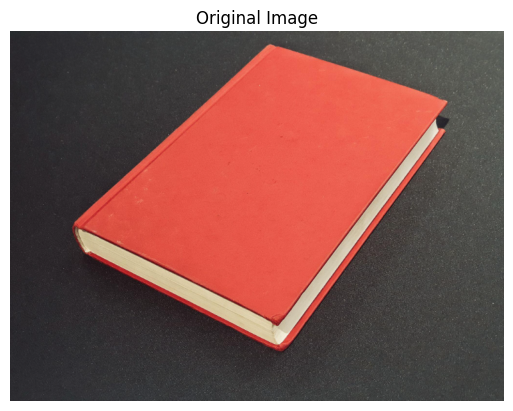

In [3]:
filename = list(uploaded.keys())[0]

img = cv2.imdecode(
    np.frombuffer(uploaded[filename], np.uint8),
    cv2.IMREAD_COLOR
)

if img is None:
    raise ValueError("Please upload a valid image.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [4]:
height, width = img.shape[:2]

pts1 = np.float32([
    [0, 0],
    [width - 1, 0],
    [0, height - 1],
    [width - 1, height - 1]
])

pts2 = np.float32([
    [width * 0.15, height * 0.10],
    [width * 0.85, height * 0.10],
    [width * 0.05, height * 0.90],
    [width * 0.95, height * 0.90]
])

print("Source points:")
print(pts1)

print("Destination points:")
print(pts2)

Source points:
[[  0.   0.]
 [770.   0.]
 [  0. 576.]
 [770. 576.]]
Destination points:
[[115.65  57.7 ]
 [655.35  57.7 ]
 [ 38.55 519.3 ]
 [732.45 519.3 ]]


In [5]:
matrix = cv2.getPerspectiveTransform(pts1, pts2)

perspective = cv2.warpPerspective(
    img,
    matrix,
    (width, height)
)

print("Perspective transformation completed")

Perspective transformation completed


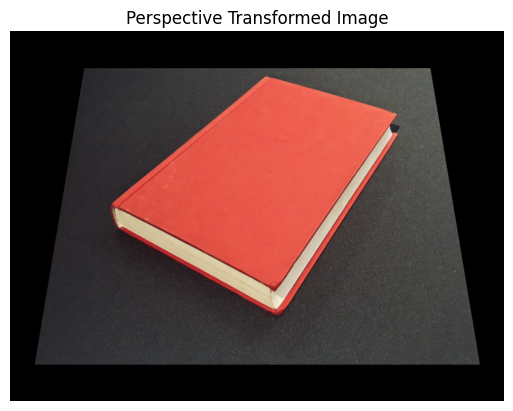

In [6]:
perspective_rgb = cv2.cvtColor(
    perspective, cv2.COLOR_BGR2RGB
)

plt.imshow(perspective_rgb)
plt.title("Perspective Transformed Image")
plt.axis("off")
plt.show()

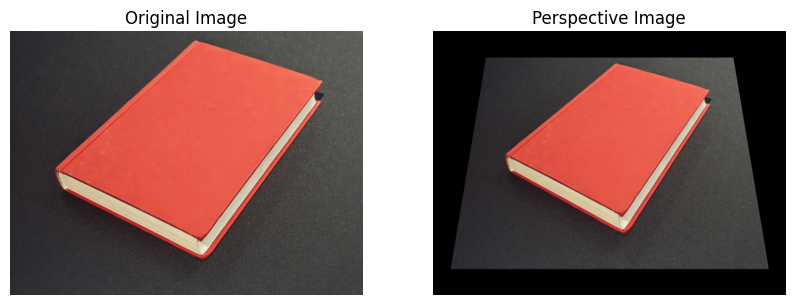

In [7]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(perspective_rgb)
plt.title("Perspective Image")
plt.axis("off")

plt.show()